In [1]:
import pandas as pd
import numpy as np                
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
sales_data = pd.read_parquet(r'Data\Cleaned_data\cleaned_data.parquet')
stores_data = pd.read_parquet(r'Data\Cleaned_data\cleaned_store_data.parquet')

In [3]:
sales_data.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday,year,month,day
Date,,,,,,,,,,,
2013-01-01,1115,2,2013-01-01,0,0,0,0,1,2013,1,1
2013-01-01,379,2,2013-01-01,0,0,0,0,1,2013,1,1
2013-01-01,378,2,2013-01-01,0,0,0,0,1,2013,1,1
2013-01-01,377,2,2013-01-01,0,0,0,0,1,2013,1,1
2013-01-01,376,2,2013-01-01,0,0,0,0,1,2013,1,1


In [4]:
stores_data.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,Basic,1270.0,9,2008,0,22,2012,NoPromoInterval
1,2,a,Basic,570.0,11,2007,1,13,2010,"Jan,Apr,Jul,Oct"
2,3,a,Basic,14130.0,12,2006,1,14,2011,"Jan,Apr,Jul,Oct"
3,4,c,Extended,620.0,9,2009,0,22,2012,NoPromoInterval
4,5,a,Basic,29910.0,4,2015,0,22,2012,NoPromoInterval


In [5]:
sales_data['Date'] = pd.to_datetime(sales_data['Date'])
# sales_data['year'] = sales_data['year'].astype('category')

In [6]:
sales_data.index.dtype

dtype('<M8[us]')

Text(0.5, 1.0, 'Correlation Matrix of Sales Data')

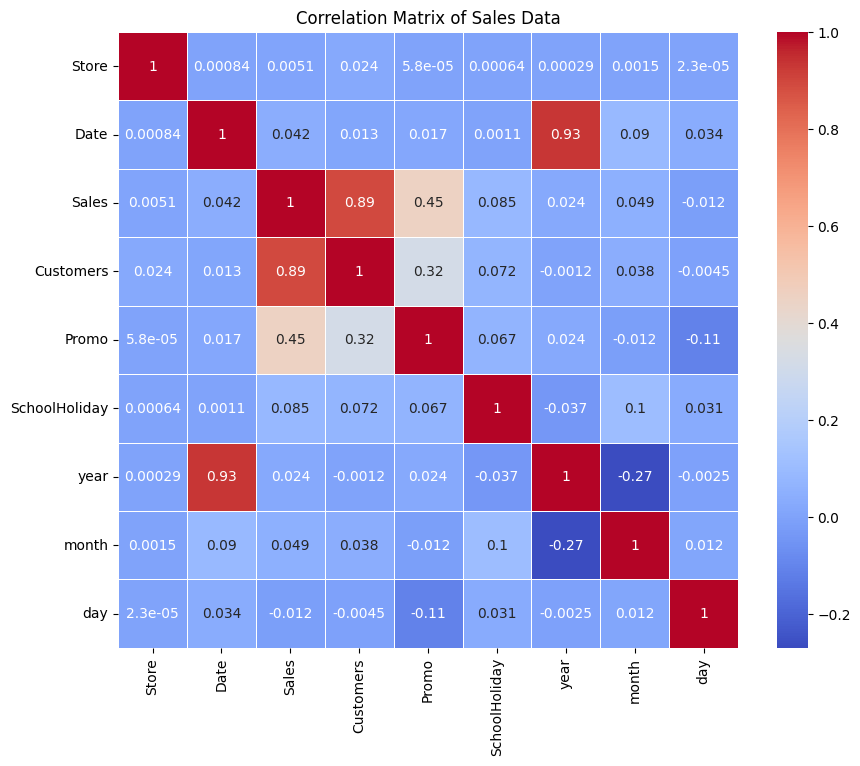

In [7]:
correlation_matrix = sales_data.drop(['Open','DayOfWeek'], axis=1).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Sales Data')

In [8]:
df = pd.merge(sales_data.reset_index(drop=True), stores_data, on='Store')
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday,year,month,day,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1115,2,2013-01-01,0,0,0,0,1,2013,1,1,d,Extended,5350.0,8,2010,1,22,2012,"Mar,Jun,Sept,Dec"
1,379,2,2013-01-01,0,0,0,0,1,2013,1,1,d,Basic,6630.0,8,2010,0,22,2012,NoPromoInterval
2,378,2,2013-01-01,0,0,0,0,1,2013,1,1,a,Extended,2140.0,8,2012,0,22,2012,NoPromoInterval
3,377,2,2013-01-01,0,0,0,0,1,2013,1,1,a,Extended,100.0,6,2010,1,18,2010,"Feb,May,Aug,Nov"
4,376,2,2013-01-01,0,0,0,0,1,2013,1,1,a,Basic,160.0,8,2012,0,22,2012,NoPromoInterval


In [9]:
df = df.sort_values(by=['Store', 'Date']).reset_index(drop=True)
#df.set_index('Date', inplace=True)
#df.drop(columns=['Open'], inplace=True)
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday,year,month,day,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,2,2013-01-01,0,0,0,0,1,2013,1,1,c,Basic,1270.0,9,2008,0,22,2012,NoPromoInterval
1,1,3,2013-01-02,5530,668,1,0,1,2013,1,2,c,Basic,1270.0,9,2008,0,22,2012,NoPromoInterval
2,1,4,2013-01-03,4327,578,1,0,1,2013,1,3,c,Basic,1270.0,9,2008,0,22,2012,NoPromoInterval
3,1,5,2013-01-04,4486,619,1,0,1,2013,1,4,c,Basic,1270.0,9,2008,0,22,2012,NoPromoInterval
4,1,6,2013-01-05,4997,635,1,0,1,2013,1,5,c,Basic,1270.0,9,2008,0,22,2012,NoPromoInterval


In [10]:
df.shape

(1017209, 20)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 20 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   SchoolHoliday              1017209 non-null  int64         
 8   year                       1017209 non-null  int32         
 9   month                      1017209 non-null  int32         
 10  day                        1017209 non-null  int32         
 11  StoreType                  1017209 non-null  str

In [12]:
df[(df['StoreType'] == 'b') & (df['DayOfWeek'] == 7)].shape[0]

2252

In [13]:
df_open=df[df['Open'] == 1]

In [14]:
df['quarter'] = df['Date'].dt.quarter.astype('category')

In [15]:

# 1. Sort by Store and Date
df = df.sort_values(["Store", "Date"])

# 2. Identify changes in Promo status per Store
promo_changed = df["Promo"] != df.groupby("Store")["Promo"].shift(1)
promo_block = promo_changed.cumsum()

# 3. Calculate consecutive promo days per block
df["consecutive_promo_days"] = df.groupby(promo_block)["Promo"].cumsum()


In [16]:
# 1. Ensure shift happens per store, not globally
df['prev_open'] = df.groupby('Store')['Open'].shift(1)

# 2. Identify every day where a closure starts (Yesterday Open=1, Today Open=0)
df['closure_start'] = (df['prev_open'] == 1) & (df['Open'] == 0)

# 3. Create a unique ID for every consecutive closure streak per store
df['closure_group'] = df.groupby('Store')['closure_start'].cumsum()

# 4. Count duration of closures and filter for refurbishments (e.g., >= 5 days)
closed_days = df[df['Open'] == 0]
refurbishments = (
    closed_days.groupby(['Store', 'closure_group'])
    .agg(
        start_date=('Date', 'min'),
        end_date=('Date', 'max'),
        duration=('Date', 'count')
    )
    .query('duration >= 5')  # Refurbishments typically last 5+ days
    .reset_index()
)


In [17]:
refurbishments.head(10)

,Store,closure_group,start_date,end_date,duration
0,25,63,2014-01-15,2014-02-11,28
1,28,96,2014-08-22,2014-09-01,11
2,57,88,2014-06-22,2014-06-30,9
3,100,30,2013-06-30,2013-07-18,19
4,102,91,2014-07-13,2014-07-23,11
5,103,0,2013-01-01,2013-07-04,185
6,105,14,2013-03-31,2013-04-28,29
7,106,30,2013-07-04,2013-07-14,11
8,123,97,2014-08-27,2014-09-09,14
9,145,73,2014-03-13,2014-03-27,15


In [18]:
refurbishments.sort_values(by=['Store', 'start_date'], inplace=True)

In [19]:

# 1. Prepare data (ensure dates are sorted)
df = df.sort_values('Date')
refurb_sorted = refurbishments.copy()
refurb_sorted['reopen_date'] = pd.to_datetime(refurb_sorted['end_date']) + pd.Timedelta(days=1)
refurb_sorted = refurb_sorted.sort_values('reopen_date')

# 2. Perform point-in-time backward lookup
merged = pd.merge_asof(
    df,
    refurb_sorted[['Store', 'reopen_date']],
    left_on='Date',
    right_on='reopen_date',
    by='Store',
    direction='backward'  # Only matches refurbishments ON or BEFORE current Date
)

# 3. Calculate exact days
df['days_since_last_refurb'] = (merged['Date'] - merged['reopen_date']).dt.days.astype('Int64')

In [20]:
refurb_sorted['start_date'] = pd.to_datetime(refurb_sorted['start_date'])
refurb_sorted = refurb_sorted.sort_values('start_date')
merged = pd.merge_asof(
    df,
    refurb_sorted[['Store', 'start_date']],
    left_on='Date',
    right_on='start_date',
    by='Store',
    direction='forward'  # Finds the first refurbishment ON or AFTER current Date
)

df['days_until_next_refurb'] = (merged['Date'] - merged['start_date']).dt.days.astype('Int64')

In [21]:
df.sort_values(by=['Store', 'Date'], inplace=True)
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday,year,month,...,Promo2SinceWeek,Promo2SinceYear,PromoInterval,quarter,consecutive_promo_days,prev_open,closure_start,closure_group,days_since_last_refurb,days_until_next_refurb
0,1,2,2013-01-01,0,0,0,0,1,2013,1,...,22,2012,NoPromoInterval,1,0,NaN,False,0,<NA>,<NA>
1,1,3,2013-01-02,5530,668,1,0,1,2013,1,...,22,2012,NoPromoInterval,1,0,0.0,False,0,<NA>,<NA>
2,1,4,2013-01-03,4327,578,1,0,1,2013,1,...,22,2012,NoPromoInterval,1,0,1.0,False,0,<NA>,-432
3,1,5,2013-01-04,4486,619,1,0,1,2013,1,...,22,2012,NoPromoInterval,1,0,1.0,False,0,<NA>,<NA>
4,1,6,2013-01-05,4997,635,1,0,1,2013,1,...,22,2012,NoPromoInterval,1,0,1.0,False,0,<NA>,<NA>


In [22]:
df[[ 'days_since_last_refurb', 'days_until_next_refurb']].describe()

,days_since_last_refurb,days_until_next_refurb
count,49427.0,31101.0
mean,332.696401,-264.650783
std,227.737589,198.089377
min,0.0,-926.0
25%,143.0,-393.0
50%,295.0,-227.0
75%,493.0,-100.0
max,925.0,0.0


In [23]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'quarter', 'consecutive_promo_days',
       'prev_open', 'closure_start', 'closure_group', 'days_since_last_refurb',
       'days_until_next_refurb'],
      dtype='str')

In [24]:
df.drop(columns=['prev_open', 'closure_start', 'closure_group'], inplace=True)

In [25]:
df.set_index('Date', inplace=True)

In [26]:

# 1. Shift Sales and Open by 7 steps per store
sales_lag_7 = df.groupby('Store')['Sales'].shift(7)
open_lag_7 = df.groupby('Store')['Open'].shift(7)

sales_lag_8 = df.groupby('Store')['Sales'].shift(8)
open_lag_8 = df.groupby('Store')['Open'].shift(8)

sales_lag_14 = df.groupby('Store')['Sales'].shift(14)
open_lag_14 = df.groupby('Store')['Open'].shift(14)

sales_lag_21 = df.groupby('Store')['Sales'].shift(21)
open_lag_21 = df.groupby('Store')['Open'].shift(21)

sales_lag_28 = df.groupby('Store')['Sales'].shift(28)
open_lag_28 = df.groupby('Store')['Open'].shift(28)


df['7th_lag'] = sales_lag_7
df['14th_lag'] = sales_lag_14
df['21st_lag'] = sales_lag_21
df['28th_lag'] = sales_lag_28

df['avg_last_3_weeks'] = df[['7th_lag', '14th_lag', '21st_lag']].mean(axis=1)

df['7th_lag'] = sales_lag_7.where(open_lag_7 == 1, np.nan)
df['8th_lag'] = sales_lag_8.where(open_lag_8 == 1, np.nan)
df['14th_lag'] = sales_lag_14.where(open_lag_14 == 1, np.nan)
df['21st_lag'] = sales_lag_21.where(open_lag_21 == 1, np.nan)
df['28th_lag'] = sales_lag_28.where(open_lag_28 == 1, np.nan)




In [27]:
# # 1. Shift Sales and Open by 7 steps per store
# customers_lag_7 = df.groupby('Store')['Customers'].shift(7)
# open_lag_7 = df.groupby('Store')['Open'].shift(7)

# # customers_lag_8 = df.groupby('Store')['Customers'].shift(8)
# # open_lag_8 = df.groupby('Store')['Open'].shift(8)

# customers_lag_14 = df.groupby('Store')['Customers'].shift(14)
# open_lag_14 = df.groupby('Store')['Open'].shift(14)

# customers_lag_21 = df.groupby('Store')['Customers'].shift(21)
# open_lag_21 = df.groupby('Store')['Open'].shift(21)

# customers_lag_28 = df.groupby('Store')['Customers'].shift(28)
# open_lag_28 = df.groupby('Store')['Open'].shift(28)


# df['7th_lag_Customers'] = customers_lag_7
# df['14th_lag_Customers'] = customers_lag_14
# df['21st_lag_Customers'] = customers_lag_21
# df['28th_lag_Customers'] = customers_lag_28

# df['avg_last_3_weeks'] = df[['7th_lag', '14th_lag', '21st_lag']].mean(axis=1)

# df['7th_lag_Customers'] = customers_lag_7.where(open_lag_7 == 1, np.nan)
# #df['8th_lag'] = sales_lag_8.where(open_lag_8 == 1, np.nan)
# df['14th_lag_Customers'] = customers_lag_14.where(open_lag_14 == 1, np.nan)
# df['21st_lag_Customers'] = customers_lag_21.where(open_lag_21 == 1, np.nan)
# df['28th_lag_Customers'] = customers_lag_28.where(open_lag_28 == 1, np.nan)

In [28]:
df['avg_last_3_weeks'].isna().sum(),df['avg_last_3_weeks'].shape[0]

(np.int64(7805), 1017209)

In [29]:
7*df['Store'].nunique()

7805

In [30]:

# 2. Shift Sales by 7 days to move the reference point back to t-7
shifted_sales = df.groupby('Store')['Sales'].shift(7)

# 3. Calculate 7-day Simple Moving Average (MA) on the shifted data
# Spans days (t-13) through (t-7)
df['ma_3d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .rolling(window=3, min_periods=3)
    .mean()
    .reset_index(level=0, drop=True)
)

df['std_3d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .rolling(window=3, min_periods=3)
    .std()
    .reset_index(level=0, drop=True)
)


df['ma_7d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .rolling(window=7, min_periods=7)
    .mean()
    .reset_index(level=0, drop=True)
)



df['ma_15d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .rolling(window=15, min_periods=10)
    .mean()
    .reset_index(level=0, drop=True)
)

df['ma_30d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .rolling(window=30, min_periods=20)
    .mean()
    .reset_index(level=0, drop=True)
)

# 4. Calculate Exponential Moving Average (EMA) on the shifted data
# Uses span=15 for a 15-day decay factor
df['ema_15d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .transform(lambda x: x.ewm(span=15, adjust=False).mean())
)

df['ema_30d_lag7'] = (
    shifted_sales.groupby(df['Store'])
    .transform(lambda x: x.ewm(span=30, adjust=False).mean())
)

In [31]:
# shifted_customers = df.groupby('Store')['Customers'].shift(7)

# # 3. Calculate 7-day Simple Moving Average (MA) on the shifted data
# # Spans days (t-13) through (t-7)
# df['ma_3d_lag7_Customers'] = (
#     shifted_customers.groupby(df['Store'])
#     .rolling(window=3, min_periods=3)
#     .mean()
#     .reset_index(level=0, drop=True)
# )

# df['std_3d_lag7_Customers'] = (
#     shifted_customers.groupby(df['Store'])
#     .rolling(window=3, min_periods=3)
#     .std()
#     .reset_index(level=0, drop=True)
# )


# df['ma_7d_lag7_Customers'] = (
#     shifted_customers.groupby(df['Store'])
#     .rolling(window=7, min_periods=7)
#     .mean()
#     .reset_index(level=0, drop=True)
# )



# df['ma_15d_lag7_Customers'] = (
#     shifted_customers.groupby(df['Store'])
#     .rolling(window=15, min_periods=10)
#     .mean()
#     .reset_index(level=0, drop=True)
# )

# df['ma_30d_lag7_Customers'] = (
#     shifted_customers.groupby(df['Store'])
#     .rolling(window=30, min_periods=20)
#     .mean()
#     .reset_index(level=0, drop=True)
# )


In [32]:
df['7_8_lag_dif'] = df['7th_lag'] -df['8th_lag'] 
df.drop(columns=['8th_lag'], inplace=True)

In [33]:
# fig, axes = plt.subplots(1,2, figsize=(10, 4))
# sns.histplot(data=df[df['Store']== 25], x='ema_7d_lag7',ax=axes[0], kde=True)
# sns.histplot(data=df[df['Store']== 25], x='ma_7d_lag7',ax=axes[1], kde=True)


In [34]:
# df['ema_7d_lag7'].replace(0, np.nan, inplace=True)
# df['ma_7d_lag7'].replace(0, np.nan, inplace=True)


In [35]:
# fig, axes = plt.subplots(1,2, figsize=(10, 4))
# sns.scatterplot(data=df[df['Open']==1].reset_index(), x='ema_7d_lag7', y='Sales',alpha=0.5, ax=axes[0])
# sns.scatterplot(data=df[df['Open']==1].reset_index(), x='ma_7d_lag7', y='Sales',alpha=0.5, ax=axes[1])

In [36]:
df[['Sales','Customers']].corr()

,Sales,Customers
Sales,1.000000,0.894711
Customers,0.894711,1.000000


              Sales  Customers
Sales      1.000000   0.894711
Customers  0.894711   1.000000


<Axes: xlabel='Customers', ylabel='Sales'>

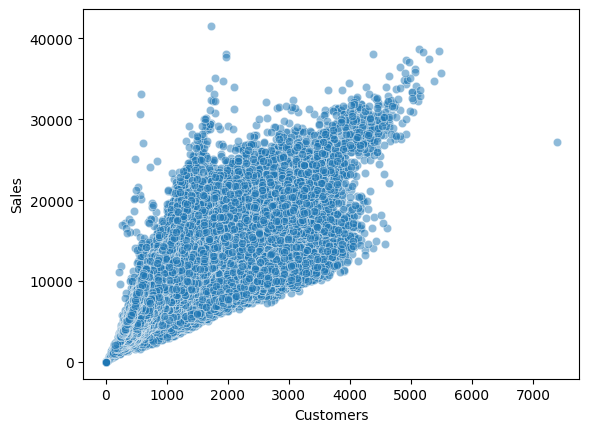

In [37]:
print(df[['Sales','Customers']].corr())
sns.scatterplot(data=df.reset_index(), x='Customers', y='Sales',alpha=0.5)

In [38]:
def add_promo2_active_feature(df):
    """
    Creates a binary column 'Is_Promo2_Active' indicating whether Promo2 
    is actively running for that store on that specific date.
    """
    df = df.copy()
    
    # 1. Map month numbers (1..12) to 3-letter month abbreviations used in Rossmann
    month_map = {
        1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr',
        5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug',
        9: 'Sept', 10: 'Oct', 11: 'Nov', 12: 'Dec'
    }
    
   
    current_month_str = df.index.month.map(month_map)
    
    # 2. Check if current month is listed inside PromoInterval
    # Vectorized string check
    is_promo_month = [
        str(month) in str(interval).split(',') 
        for month, interval in zip(current_month_str, df['PromoInterval'])
    ]
    
    # 3. Promo2 is ACTIVE only if:
    #    a) Store participates (Promo2 == 1)
    #    b) Current month is in PromoInterval
    df['Is_Promo2_Active'] = (df['Promo2'] == 1) & np.array(is_promo_month)
    df['Is_Promo2_Active'] = df['Is_Promo2_Active'].astype(int)
    
    return df

# --- Usage ---
df = add_promo2_active_feature(df)


In [39]:
df.columns

Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'quarter', 'consecutive_promo_days',
       'days_since_last_refurb', 'days_until_next_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks', 'ma_3d_lag7',
       'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7', 'ma_30d_lag7',
       'ema_15d_lag7', 'ema_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active'],
      dtype='str')

In [40]:
(df['Promo2'] != df['Is_Promo2_Active']).sum()

np.int64(334386)

In [41]:
df = df.sort_values(["Store", "Date"])

# 2. Identify changes in Promo status per Store
promo_changed = df["Promo2"] != df.groupby("Store")["Promo2"].shift(1)
promo_block = promo_changed.cumsum()

# 3. Calculate consecutive promo days per block
df["consecutive_promo2_days"] = df.groupby(promo_block)["Promo2"].cumsum()

In [42]:
df.reset_index(inplace=True)

In [43]:
df.set_index('Date', inplace=True)

In [44]:
df.columns

Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'quarter', 'consecutive_promo_days',
       'days_since_last_refurb', 'days_until_next_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks', 'ma_3d_lag7',
       'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7', 'ma_30d_lag7',
       'ema_15d_lag7', 'ema_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days'],
      dtype='str')

In [45]:
df['CompetitionOpenSince'] = df['CompetitionOpenSinceMonth'].astype(str)+'-'+df['CompetitionOpenSinceYear'].astype(str)
df['CompetitionOpenSince'] = pd.to_datetime(df['CompetitionOpenSince'], format='%m-%Y', errors='coerce')
df['CompetitionOpenSince'] = (df.index - df['CompetitionOpenSince']).dt.days

df['Promo2Since'] = df['Promo2SinceWeek'].astype(str)+'-'+df['Promo2SinceYear'].astype(str)
df['Promo2Since'] = pd.to_datetime(df['Promo2Since'].astype(str) + '-1', format='%W-%Y-%w', errors='coerce')
df['Promo2Since'] = (df.index - df['Promo2Since']).dt.days

df.drop(columns=['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear'], inplace=True)

df[['Promo2Since', 'CompetitionOpenSince']].describe()

,Promo2Since,CompetitionOpenSince
count,1.017209e+06,1.017209e+06
mean,7.222896e+02,1.691367e+03
std,5.030079e+02,1.839756e+03
min,-8.880000e+02,-9.420000e+02
25%,3.910000e+02,8.890000e+02
50%,7.110000e+02,1.402000e+03
75%,1.034000e+03,2.234000e+03
max,2.188000e+03,4.221400e+04


In [46]:
df.loc[df['CompetitionOpenSince'] < 0, 'CompetitionOpenSince'] = 0
df.loc[df['Promo2Since'] < 0, 'Promo2Since'] = 0

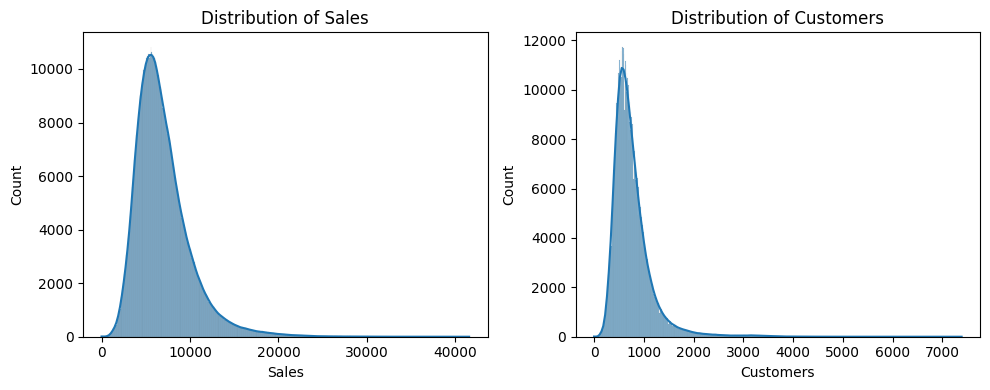

In [47]:
fig, axes = plt.subplots(1,2, figsize=(10, 4))
sns.histplot(df_open['Sales'], ax=axes[0], kde=True)
axes[0].set_title('Distribution of Sales')
sns.histplot(df_open['Customers'], ax=axes[1], kde=True)
axes[1].set_title('Distribution of Customers')
plt.tight_layout()
plt.show()

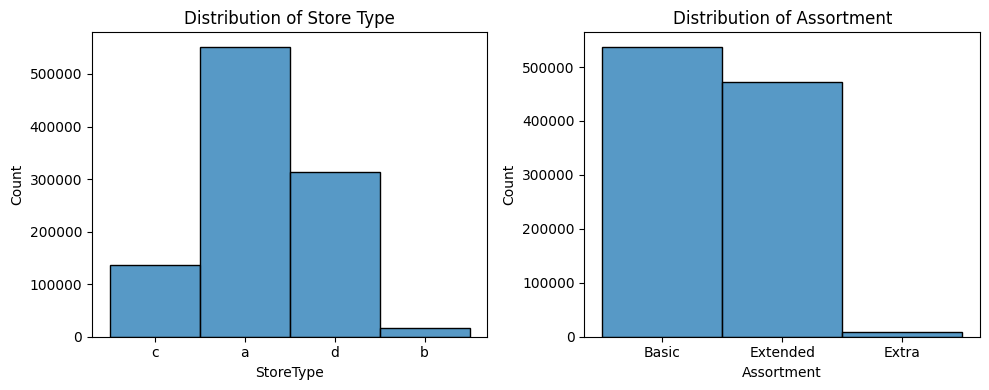

In [48]:
fig, axes = plt.subplots(1,2, figsize=(10, 4))
sns.histplot(df['StoreType'], ax=axes[0]) # type: ignore
axes[0].set_title('Distribution of Store Type')
sns.histplot(df['Assortment'], ax=axes[1]) # type: ignore
axes[1].set_title('Distribution of Assortment')
plt.tight_layout()
plt.show()

In [49]:
print(f'percentage of Extra assortment: {df["Assortment"].value_counts()["Extra"] / len(df) * 100:.2f}%')
print(f'percentage of b Store Type: {df["StoreType"].value_counts()["b"] / len(df) * 100:.2f}%')

percentage of Extra assortment: 0.82%
percentage of b Store Type: 1.56%


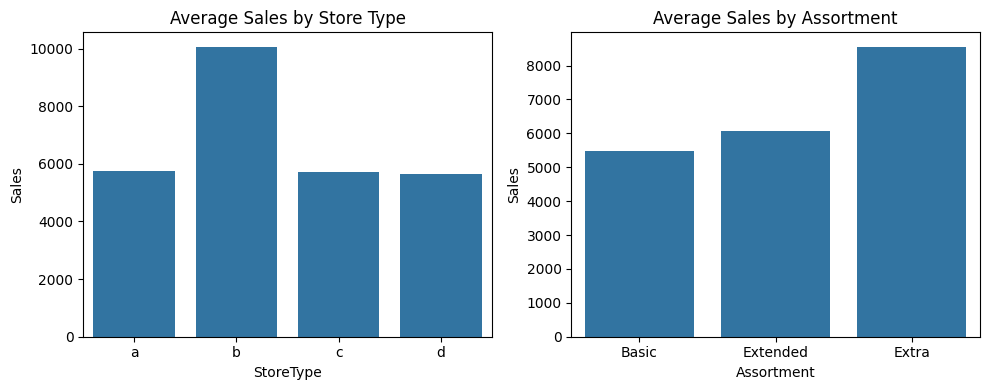

In [50]:
fig, axes = plt.subplots(1,2, figsize=(10, 4))
sns.barplot(x='StoreType', y='Sales', data=df.groupby('StoreType')['Sales'].mean().reset_index(), ax=axes[0])
axes[0].set_title('Average Sales by Store Type')
sns.barplot(x='Assortment', y='Sales', data=df.groupby('Assortment')['Sales'].mean().reset_index(), ax=axes[1])
axes[1].set_title('Average Sales by Assortment')
plt.tight_layout()
plt.show()

In [51]:
df['DayOfWeek'].unique()

array([2, 3, 4, 5, 6, 7, 1])

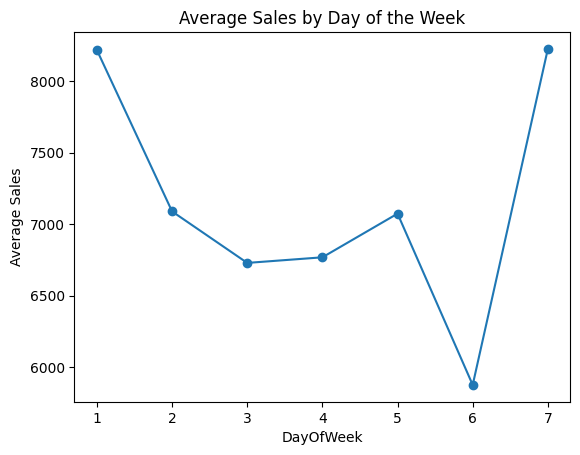

In [52]:
df_open.groupby('DayOfWeek')['Sales'].mean().plot(kind='line', marker='o')
plt.title('Average Sales by Day of the Week')
plt.xticks( rotation=0)
plt.ylabel('Average Sales')
plt.show()

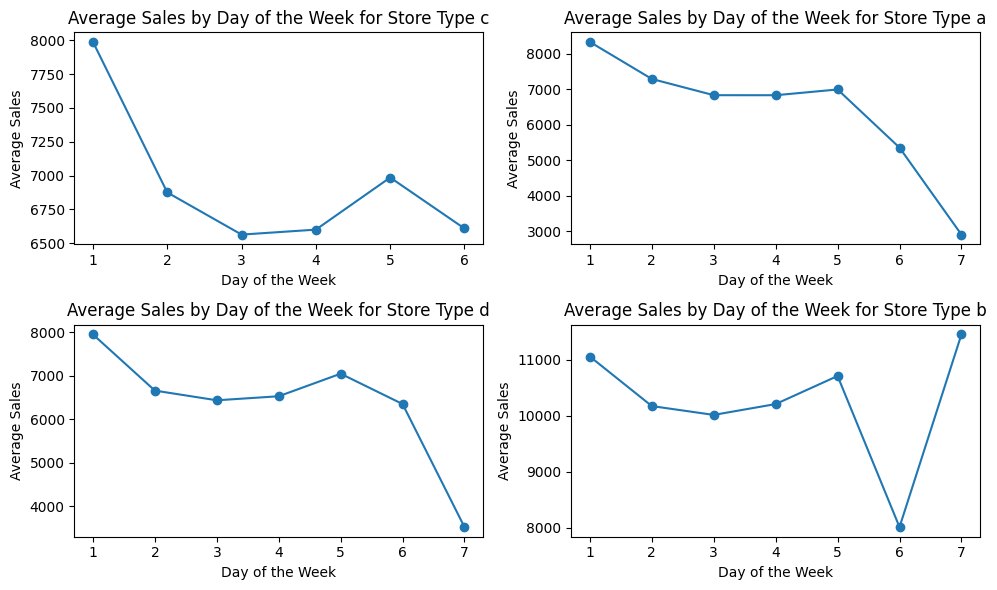

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(10,6))
for i, store_type in enumerate(df['StoreType'].unique()):
    ax = axes[i//2, i%2]
    df_open[df_open['StoreType'] == store_type].groupby('DayOfWeek')['Sales'].mean().plot(kind='line', marker='o', ax=ax)
    ax.set_title(f'Average Sales by Day of the Week for Store Type {store_type}')
    ax.set_xlabel('Day of the Week')
    ax.set_ylabel('Average Sales')
plt.tight_layout()
plt.show()


In [54]:
df['DayOfWeek'].unique()

array([2, 3, 4, 5, 6, 7, 1])

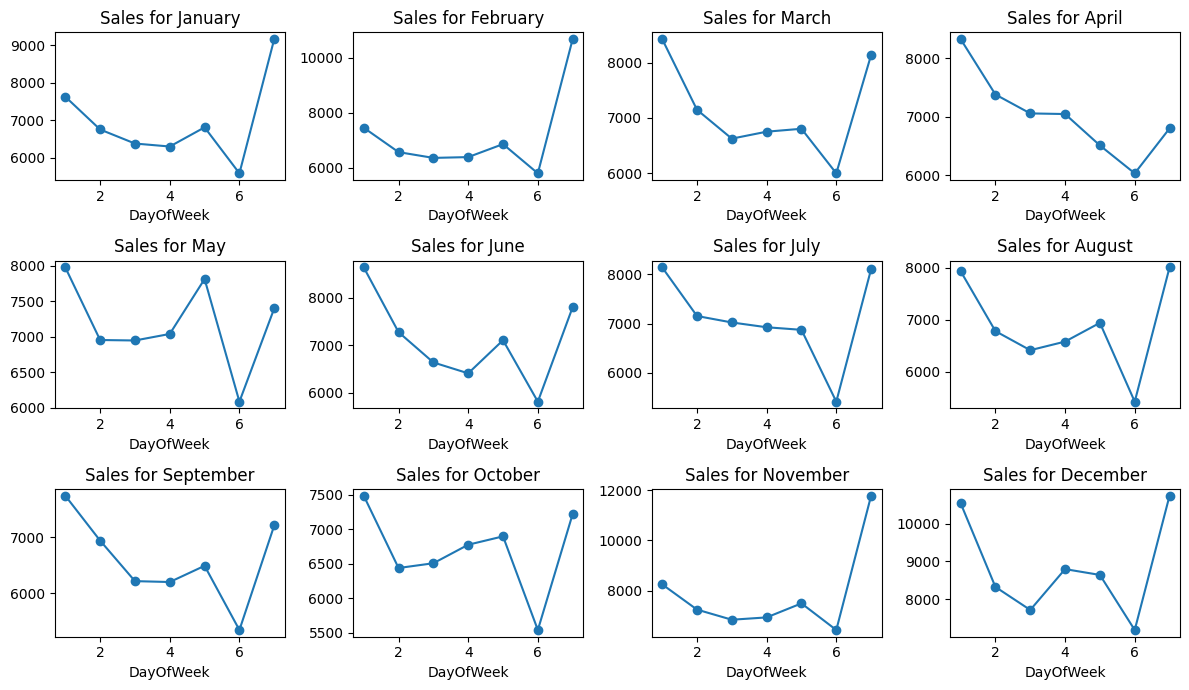

In [55]:
fig, axes = plt.subplots(3, 4, figsize=(12, 7))
num_to_month = {1: 'January', 2: 'February', 3: 'March', 4: 'April', 5: 'May', 6: 'June',
              7: 'July', 8: 'August', 9: 'September', 10: 'October', 11: 'November', 12: 'December'}
for i, month in enumerate(np.sort(df["month"].unique())):
    ax = axes[i//4, i%4]
    df_open[df_open["month"] == month].groupby('DayOfWeek')['Sales'].mean().plot(kind='line', marker='o', ax=ax)
    ax.set_title(f'Sales for {num_to_month[month]}')
plt.tight_layout()

    

In [56]:
df_open.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval'],
      dtype='str')

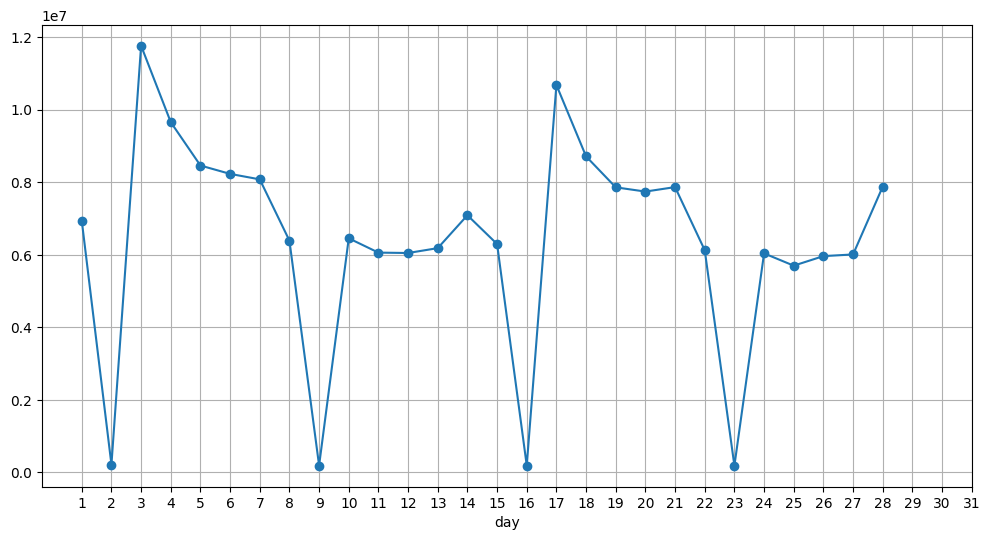

In [57]:
plt.figure(figsize=(12, 6))
df_open[(df_open["month"] == 2) & (df_open["year"] == 2014)].groupby('day')['Sales'].sum().plot(kind='line', marker='o')
plt.grid()
plt.xticks(range(1, 32))
plt.show()

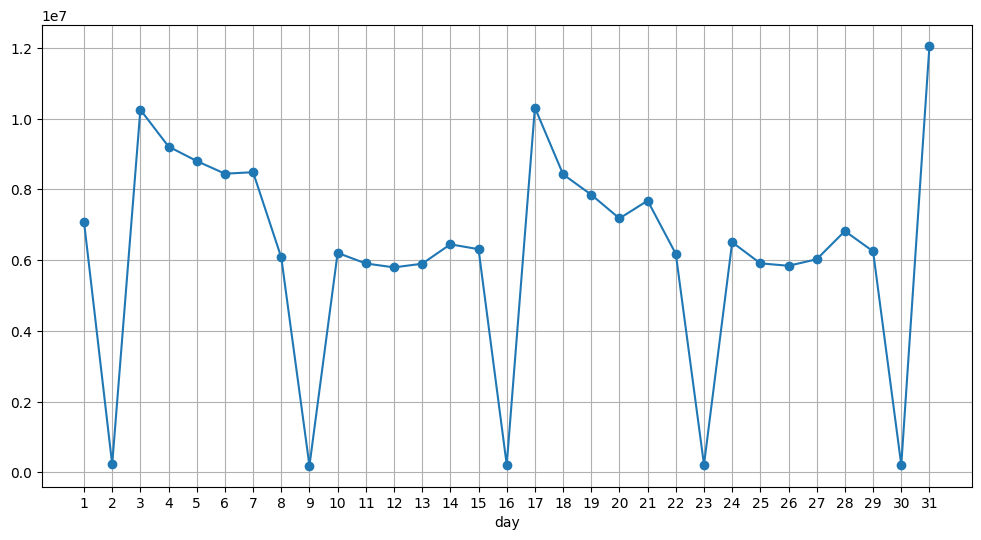

In [58]:
plt.figure(figsize=(12, 6))
df_open[(df_open["month"] == 3) & (df_open["year"] == 2014)].groupby('day')['Sales'].sum().plot(kind='line', marker='o')
plt.grid()
plt.xticks(range(1, 32))
plt.show()

In [59]:
df.reset_index(inplace=True)

In [60]:
# 1. Ensure Date is datetime format
df['Date'] = pd.to_datetime(df['Date'])

# 2. Calculate Week of Month (1 to 5)
df['week_of_month'] = (df['Date'].dt.day - 1) // 7 + 1

# 3. Calculate average sales for each year, month, and week
weekly_avg = (
    df[df['Open']==1].groupby(['year', 'month', 'week_of_month'])['Sales']
    .mean()
    .reset_index()
)


# 4. Shift month by +1 to pair last month's data with current month
weekly_avg['month'] += 1
weekly_avg.loc[weekly_avg['month'] == 13, 'year'] += 1
weekly_avg.loc[weekly_avg['month'] == 13, 'month'] = 1

weekly_avg.rename(columns={'Sales': 'last_month_same_week_avg'}, inplace=True)

# 5. Merge back to main DataFrame
df = df.merge(weekly_avg, on=['year', 'month', 'week_of_month'], how='left')

In [61]:
df['DayOfWeek'].unique()

array([2, 3, 4, 5, 6, 7, 1])

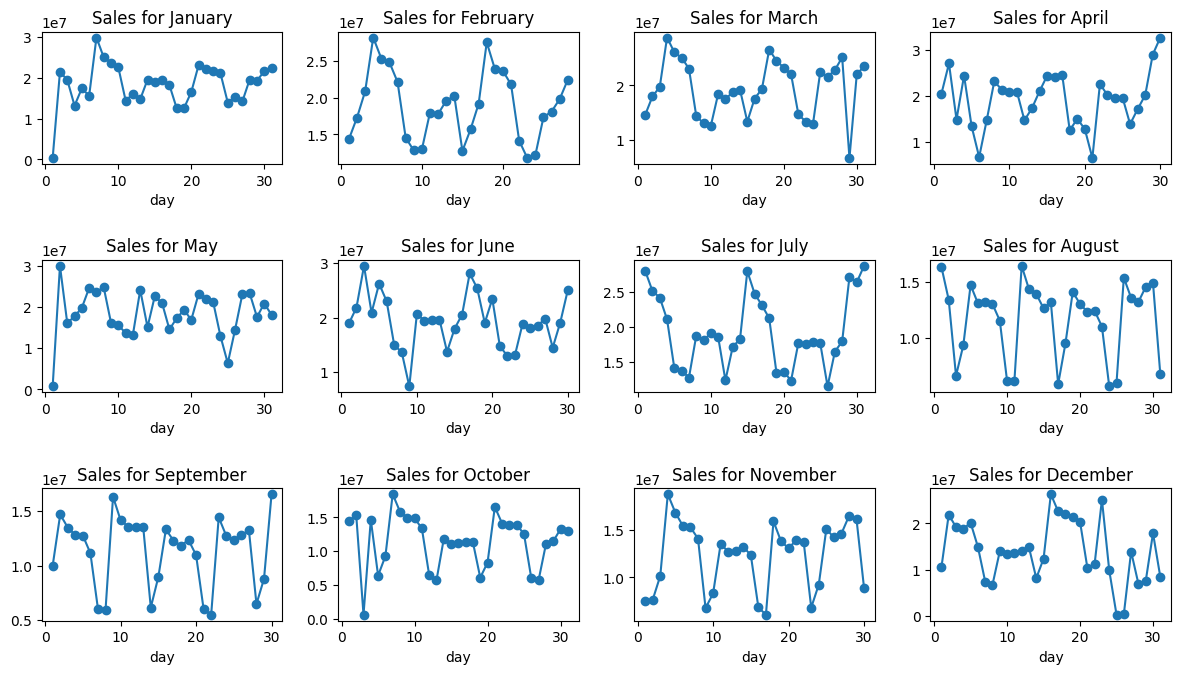

In [62]:
fig, axes = plt.subplots(3, 4, figsize=(12, 7))
num_to_month = {1: 'January', 2: 'February', 3: 'March', 4: 'April', 5: 'May', 6: 'June',
              7: 'July', 8: 'August', 9: 'September', 10: 'October', 11: 'November', 12: 'December'}
for i, month in enumerate(np.sort(df["month"].unique())):
    ax = axes[i//4, i%4]
    df[df["month"] == month].groupby('day')['Sales'].sum().plot(kind='line', marker='o', ax=ax)
    ax.set_title(f'Sales for {num_to_month[month]}')
plt.tight_layout()

In [63]:
df.set_index('Date', inplace=True)

In [64]:
# df['end_of_month'] = df.index.is_month_end.astype(int)
# df['is_weekend'] = df.index.dayofweek.isin([5, 6]).astype(int)
# df['is_monday'] = df.index.dayofweek.isin([0]).astype(int)
# df['is_saturday'] = df.index.dayofweek.isin([5]).astype(int)
# df['is_sunday'] = df.index.dayofweek.isin([6]).astype(int)
# df['is_year_end'] = df.index.is_year_end.astype(int)
# df['is_quarter_end'] = df.index.is_quarter_end.astype(int)


In [65]:
df['promo_x_dayofweek'] = df['Promo'].astype(str) + "_" + df['DayOfWeek'].astype(str)
df['promo_x_storetype'] = df['Promo'].astype(str) + "_" + df['StoreType'].astype(str)

df['promo2_x_dayofweek'] = df['Is_Promo2_Active'].astype(str) + "_" + df['DayOfWeek'].astype(str)
df['promo2_x_storetype'] = df['Is_Promo2_Active'].astype(str) + "_" + df['StoreType'].astype(str)

In [66]:
df['SchoolHoliday'].value_counts()

SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64

In [67]:
df['days_till_next_holiday'] = np.nan
holiday_dates = pd.Series(df[df['SchoolHoliday'] == 1].index.unique()).sort_values().values

for i, date in enumerate(holiday_dates):
    if i == 0:
        mask = df.index <= date
    else:
        mask = (df.index > holiday_dates[i-1]) & (df.index <= date)
    
    
    df.loc[mask, 'days_till_next_holiday'] = (date - df.loc[mask].index).days

In [68]:

df['days_after_holiday'] = np.nan
holiday_dates = pd.Series(df[df['SchoolHoliday'] == 1].index.unique()).sort_values().values


for i, date in enumerate(holiday_dates):
    if i == len(holiday_dates) - 1:
        mask = df.index >= date
    else:
        # Applies to dates from this holiday up to (but not including) the next holiday
        mask = (df.index >= date) & (df.index < holiday_dates[i + 1])
    
    # Calculate difference in days using .loc
    df.loc[mask, 'days_after_holiday'] = (df.loc[mask].index - date).days



In [69]:
df[['days_till_next_holiday', 'days_after_holiday']].describe()

,days_till_next_holiday,days_after_holiday
count,1.017209e+06,1.017209e+06
mean,5.474465e+00,5.463848e+00
std,9.053611e+00,9.050056e+00
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00
75%,8.000000e+00,8.000000e+00
max,4.700000e+01,4.700000e+01


In [70]:
df.columns

Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'Promo2', 'PromoInterval', 'quarter',
       'consecutive_promo_days', 'days_since_last_refurb',
       'days_until_next_refurb', '7th_lag', '14th_lag', '21st_lag', '28th_lag',
       'avg_last_3_weeks', 'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7',
       'ma_15d_lag7', 'ma_30d_lag7', 'ema_15d_lag7', 'ema_30d_lag7',
       '7_8_lag_dif', 'Is_Promo2_Active', 'consecutive_promo2_days',
       'CompetitionOpenSince', 'Promo2Since', 'week_of_month',
       'last_month_same_week_avg', 'promo_x_dayofweek', 'promo_x_storetype',
       'promo2_x_dayofweek', 'promo2_x_storetype', 'days_till_next_holiday',
       'days_after_holiday'],
      dtype='str')

In [71]:
df['DayOfWeek'].unique()

array([2, 3, 4, 5, 6, 7, 1])

In [72]:
df.shape

(1017209, 44)

<Axes: xlabel='month'>

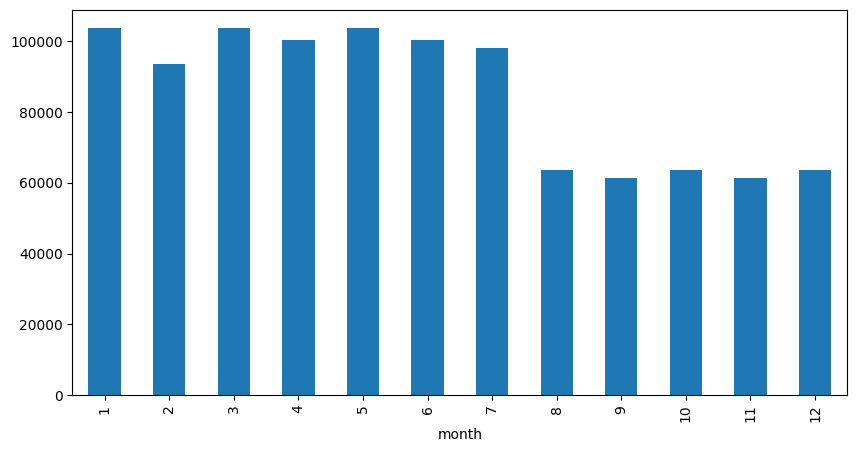

In [73]:
df['month'].value_counts().sort_index().plot(kind='bar', figsize=(10, 5))

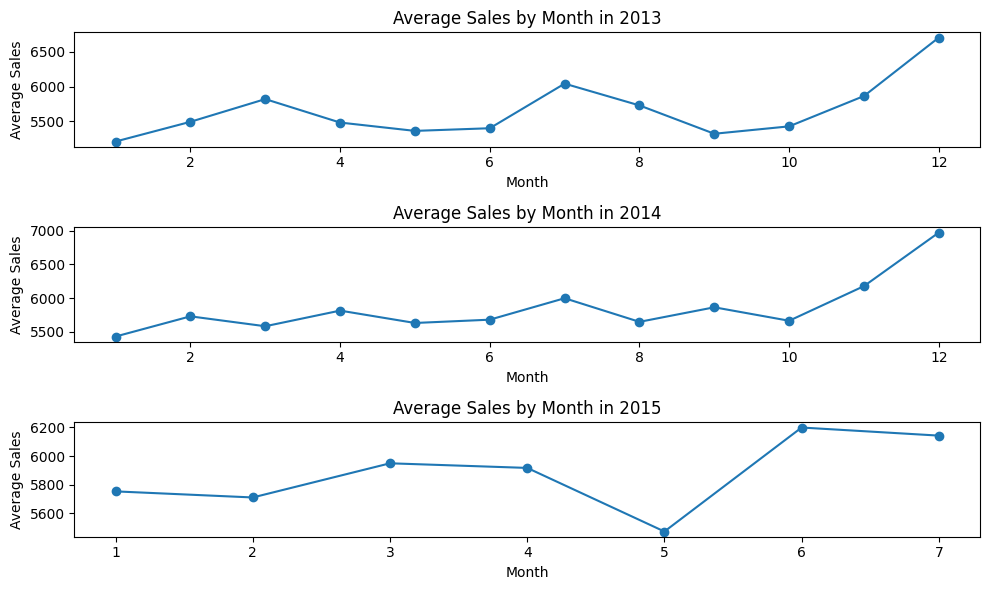

In [74]:
fig, axes = plt.subplots(3,1, figsize=(10, 6))
df[df['year'] == 2013].groupby(df[df['year'] == 2013].index.month)['Sales'].mean().plot(kind='line', marker='o', ax=axes[0])
axes[0].set_title('Average Sales by Month in 2013')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average Sales')

df[df['year'] == 2014].groupby(df[df['year'] == 2014].index.month)['Sales'].mean().plot(kind='line', marker='o', ax=axes[1])
axes[1].set_title('Average Sales by Month in 2014')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Sales')

df[df['year'] == 2015].groupby(df[df['year'] == 2015].index.month)['Sales'].mean().plot(kind='line', marker='o', ax=axes[2])
axes[2].set_title('Average Sales by Month in 2015')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Average Sales')

plt.tight_layout()
plt.show()

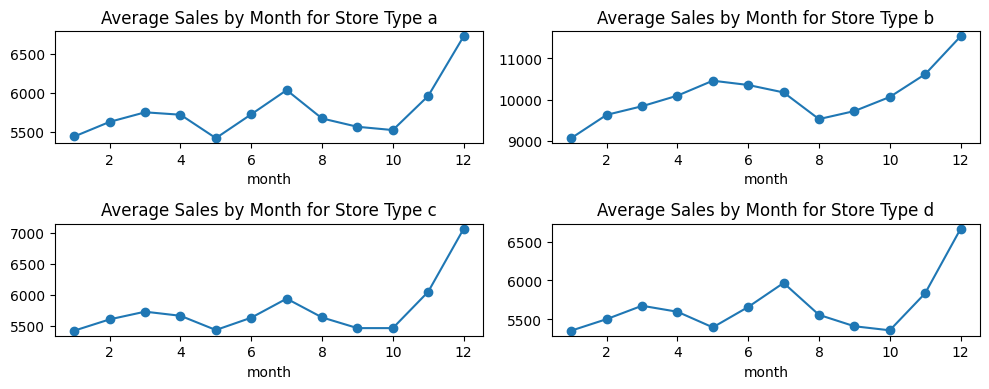

In [75]:
fig, axes = plt.subplots(2,2, figsize=(10, 4))
df[df['StoreType'] == 'a'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Store Type a', ax=axes[0, 0])
df[df['StoreType'] == 'b'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Store Type b', ax=axes[0, 1])
df[df['StoreType'] == 'c'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Store Type c', ax=axes[1, 0])
df[df['StoreType'] == 'd'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Store Type d', ax=axes[1, 1])
axes[0, 0].set_title('Average Sales by Month for Store Type a')
axes[0, 1].set_title('Average Sales by Month for Store Type b')
axes[1, 0].set_title('Average Sales by Month for Store Type c')
axes[1, 1].set_title('Average Sales by Month for Store Type d')
plt.tight_layout()
plt.show()

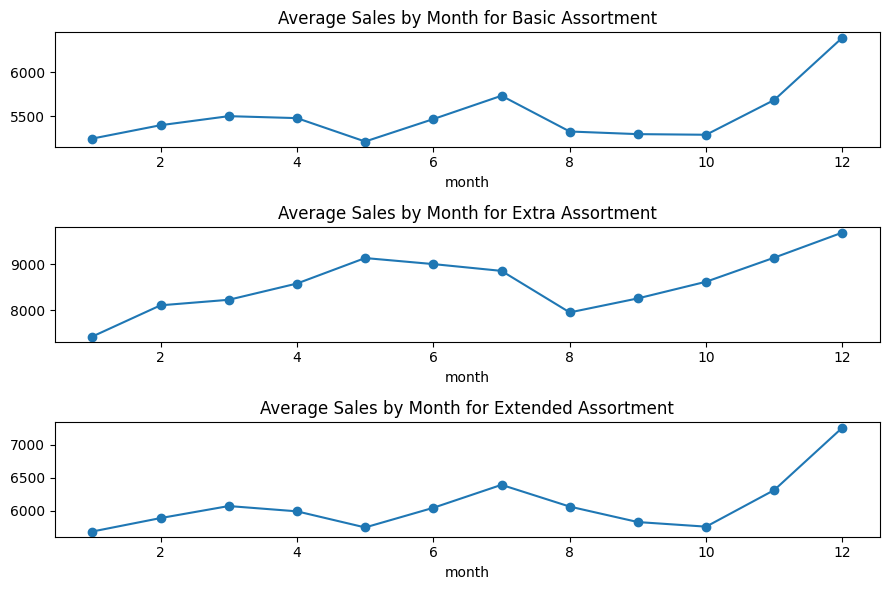

In [76]:
fig, axes = plt.subplots(3,1, figsize=(9, 6))
df[df['Assortment'] == 'Basic'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Assortment a', ax=axes[0])
df[df['Assortment'] == 'Extra'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Assortment b', ax=axes[1])
df[df['Assortment'] == 'Extended'].groupby('month') ['Sales'].mean().plot(kind='line', marker='o', label='Assortment c', ax=axes[2])


axes[0].set_title('Average Sales by Month for Basic Assortment')
axes[1].set_title('Average Sales by Month for Extra Assortment')
axes[2].set_title('Average Sales by Month for Extended Assortment')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Average Sales by Assortment and Store Type')

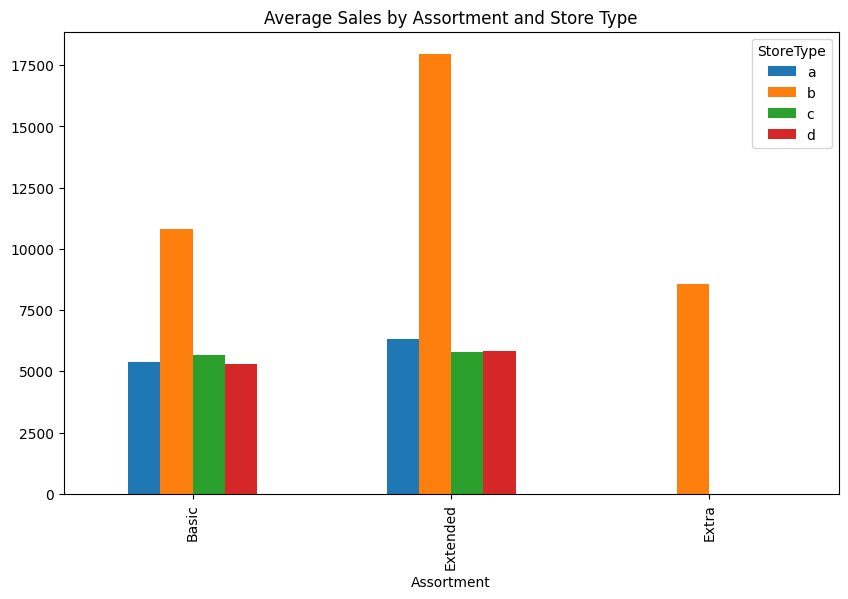

In [77]:
df.groupby(['Assortment', 'StoreType'])['Sales'].mean().unstack().plot(kind='bar', figsize=(10, 6))
plt.title('Average Sales by Assortment and Store Type')

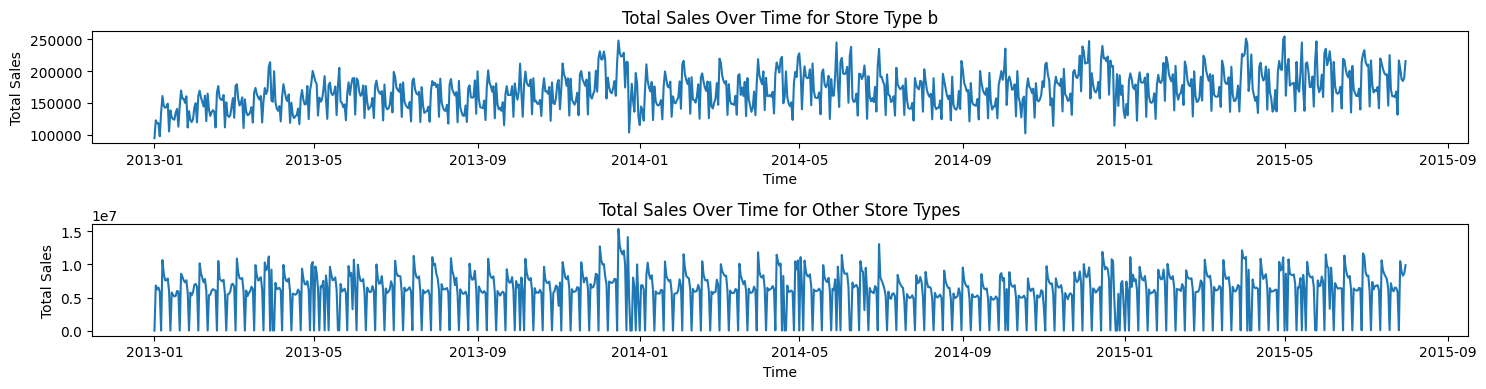

In [78]:
df_b=df[df['StoreType'] == 'b']
df_rest=df[df['StoreType'] != 'b']

plt.figure(figsize=(15, 4))
plt.subplot(2, 1, 1)
sns.lineplot(x=df_b.groupby(df_b.index)['Sales'].mean().index, y=df_b.groupby(df_b.index)['Sales'].sum())
plt.title('Total Sales Over Time for Store Type b')
plt.xlabel('Time')
plt.ylabel('Total Sales')

plt.subplot(2, 1, 2)
sns.lineplot(x=df_rest.groupby(df_rest.index)['Sales'].mean().index, y=df_rest.groupby(df_rest.index)['Sales'].sum())
plt.title('Total Sales Over Time for Other Store Types')
plt.xlabel('Time')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Total Sales Over Time')

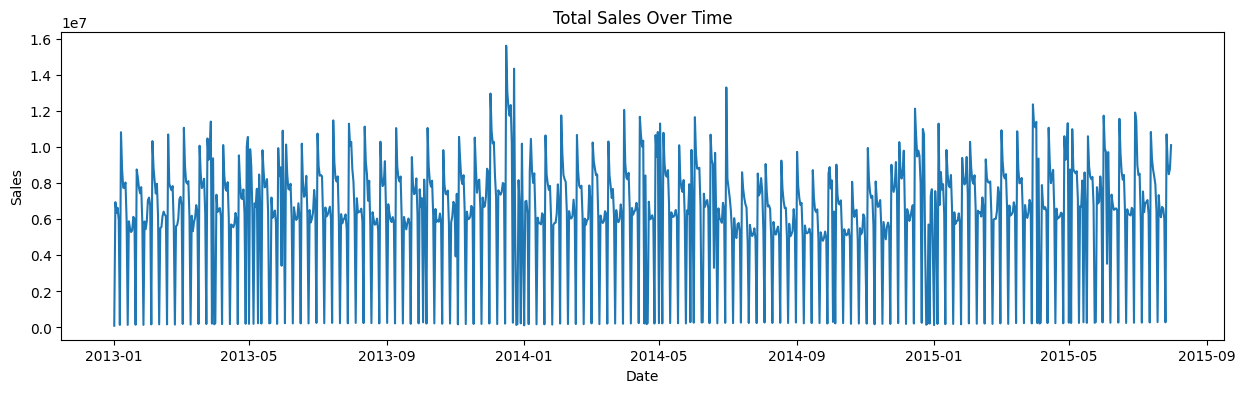

In [79]:
plt.figure(figsize=(15, 4))
sns.lineplot(x=df.groupby(df.index)['Sales'].sum().index, y=df.groupby(df.index)['Sales'].sum())
plt.title('Total Sales Over Time')

In [80]:
df['DayOfWeek'].unique()

array([2, 3, 4, 5, 6, 7, 1])

In [81]:
# df[df['year'] == 2013].groupby(df[df['year'] == 2013].index)['Sales'].sum()

In [82]:
# from statsmodels.tsa.seasonal import seasonal_decompose

# result = seasonal_decompose(df['Sales'] , model='additive', period=12)
# plt.figure(figsize=(15, 8))
# result.plot()
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

In [83]:
# from statsmodels.graphics.tsaplots import plot_acf
# import matplotlib.pyplot as plt

# # Assuming prophet_df is already defined and contains the 'y' (Sales) column.
# # If not, you might need to run the cell that creates prophet_df first.

# plt.figure(figsize=(12, 6))
# plot_acf(df.groupby(df.index)['Sales'].mean(), lags=7, ax=plt.gca())
# plt.title('Autocorrelation of Sales (Up to 15 Lags)')
# plt.xlabel('Lags')
# plt.ylabel('Autocorrelation')
# plt.grid(True)
# plt.show()

In [84]:
# store_1_2015=store_1[store_1.index.year==2015]
# store_1_2015.groupby(store_1_2015.index.month)['Sales'].sum().plot()

<Axes: ylabel='Frequency'>

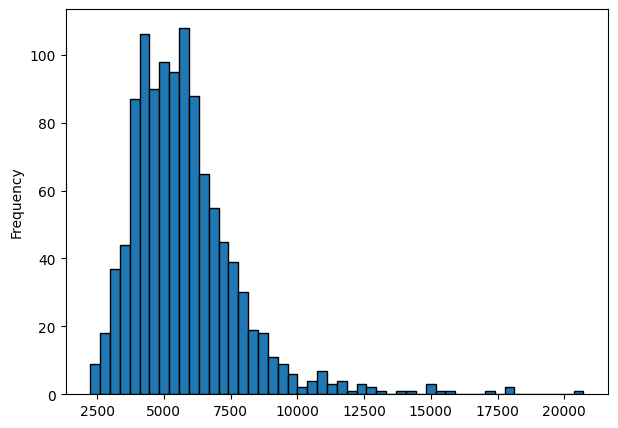

In [85]:
df.groupby('Store')['Sales'].mean().plot(kind='hist', figsize=(7, 5),bins=50,edgecolor='black')


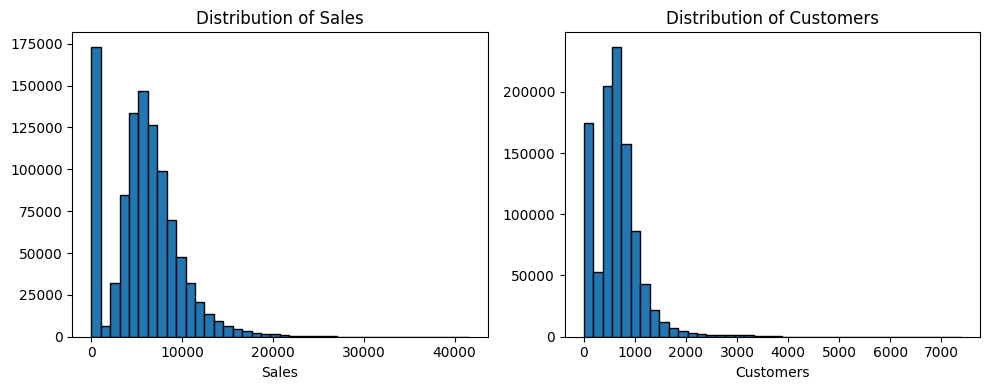

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df['Sales'], bins=40,edgecolor='black')
axes[0].set_title('Distribution of Sales')
axes[0].set_xlabel('Sales')
axes[1].hist(df['Customers'], bins=40,edgecolor='black')
axes[1].set_title('Distribution of Customers')
axes[1].set_xlabel('Customers')
plt.tight_layout()
plt.show()

In [87]:
# df.reset_index('Date', inplace=True)
# df.drop(columns=['Date'], inplace=True)

In [88]:
df.head()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,year,month,day,...,CompetitionOpenSince,Promo2Since,week_of_month,last_month_same_week_avg,promo_x_dayofweek,promo_x_storetype,promo2_x_dayofweek,promo2_x_storetype,days_till_next_holiday,days_after_holiday
Date,,,,,,,,,,,,,,,,,,,,,
2013-01-01,1,2,0,0,0,0,1,2013,1,1,...,1583,218,1,NaN,0_2,0_c,0_2,0_c,0.0,0.0
2013-01-02,1,3,5530,668,1,0,1,2013,1,2,...,1584,219,1,NaN,0_3,0_c,0_3,0_c,0.0,0.0
2013-01-03,1,4,4327,578,1,0,1,2013,1,3,...,1585,220,1,NaN,0_4,0_c,0_4,0_c,0.0,0.0
2013-01-04,1,5,4486,619,1,0,1,2013,1,4,...,1586,221,1,NaN,0_5,0_c,0_5,0_c,0.0,0.0
2013-01-05,1,6,4997,635,1,0,1,2013,1,5,...,1587,222,1,NaN,0_6,0_c,0_6,0_c,0.0,0.0


In [89]:
df.index

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06', '2013-01-07', '2013-01-08',
               '2013-01-09', '2013-01-10',
               ...
               '2015-07-22', '2015-07-23', '2015-07-24', '2015-07-25',
               '2015-07-26', '2015-07-27', '2015-07-28', '2015-07-29',
               '2015-07-30', '2015-07-31'],
              dtype='datetime64[us]', name='Date', length=1017209, freq=None)

In [90]:
df=df[df['Open']==1]

In [91]:
df['DayOfWeek'].unique()

array([3, 4, 5, 6, 1, 2, 7])

In [92]:
df.columns

Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'Promo2', 'PromoInterval', 'quarter',
       'consecutive_promo_days', 'days_since_last_refurb',
       'days_until_next_refurb', '7th_lag', '14th_lag', '21st_lag', '28th_lag',
       'avg_last_3_weeks', 'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7',
       'ma_15d_lag7', 'ma_30d_lag7', 'ema_15d_lag7', 'ema_30d_lag7',
       '7_8_lag_dif', 'Is_Promo2_Active', 'consecutive_promo2_days',
       'CompetitionOpenSince', 'Promo2Since', 'week_of_month',
       'last_month_same_week_avg', 'promo_x_dayofweek', 'promo_x_storetype',
       'promo2_x_dayofweek', 'promo2_x_storetype', 'days_till_next_holiday',
       'days_after_holiday'],
      dtype='str')

In [93]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 844392 entries, 2013-01-02 to 2015-07-31
Data columns (total 44 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   Store                     844392 non-null  int64   
 1   DayOfWeek                 844392 non-null  int64   
 2   Sales                     844392 non-null  int64   
 3   Customers                 844392 non-null  int64   
 4   Open                      844392 non-null  int64   
 5   Promo                     844392 non-null  int64   
 6   SchoolHoliday             844392 non-null  int64   
 7   year                      844392 non-null  int32   
 8   month                     844392 non-null  int32   
 9   day                       844392 non-null  int32   
 10  StoreType                 844392 non-null  str     
 11  Assortment                844392 non-null  str     
 12  CompetitionDistance       844392 non-null  float64 
 13  Promo2                  

In [94]:
df.index

DatetimeIndex(['2013-01-02', '2013-01-03', '2013-01-04', '2013-01-05',
               '2013-01-07', '2013-01-08', '2013-01-09', '2013-01-10',
               '2013-01-11', '2013-01-12',
               ...
               '2015-07-21', '2015-07-22', '2015-07-23', '2015-07-24',
               '2015-07-25', '2015-07-27', '2015-07-28', '2015-07-29',
               '2015-07-30', '2015-07-31'],
              dtype='datetime64[us]', name='Date', length=844392, freq=None)

In [95]:
sales_data['year'] = sales_data['year'].astype('category')

In [96]:
df['quarter'] = df['quarter'].astype('category')  # Convert quarter to category type

In [97]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 844392 entries, 2013-01-02 to 2015-07-31
Data columns (total 44 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   Store                     844392 non-null  int64   
 1   DayOfWeek                 844392 non-null  int64   
 2   Sales                     844392 non-null  int64   
 3   Customers                 844392 non-null  int64   
 4   Open                      844392 non-null  int64   
 5   Promo                     844392 non-null  int64   
 6   SchoolHoliday             844392 non-null  int64   
 7   year                      844392 non-null  int32   
 8   month                     844392 non-null  int32   
 9   day                       844392 non-null  int32   
 10  StoreType                 844392 non-null  str     
 11  Assortment                844392 non-null  str     
 12  CompetitionDistance       844392 non-null  float64 
 13  Promo2                  

In [98]:
df.drop(columns=['PromoInterval'], inplace=True)

In [99]:
# df.reset_index(inplace=True)

In [100]:
df.columns

Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'Promo2', 'quarter', 'consecutive_promo_days',
       'days_since_last_refurb', 'days_until_next_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks', 'ma_3d_lag7',
       'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7', 'ma_30d_lag7',
       'ema_15d_lag7', 'ema_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days', 'CompetitionOpenSince', 'Promo2Since',
       'week_of_month', 'last_month_same_week_avg', 'promo_x_dayofweek',
       'promo_x_storetype', 'promo2_x_dayofweek', 'promo2_x_storetype',
       'days_till_next_holiday', 'days_after_holiday'],
      dtype='str')

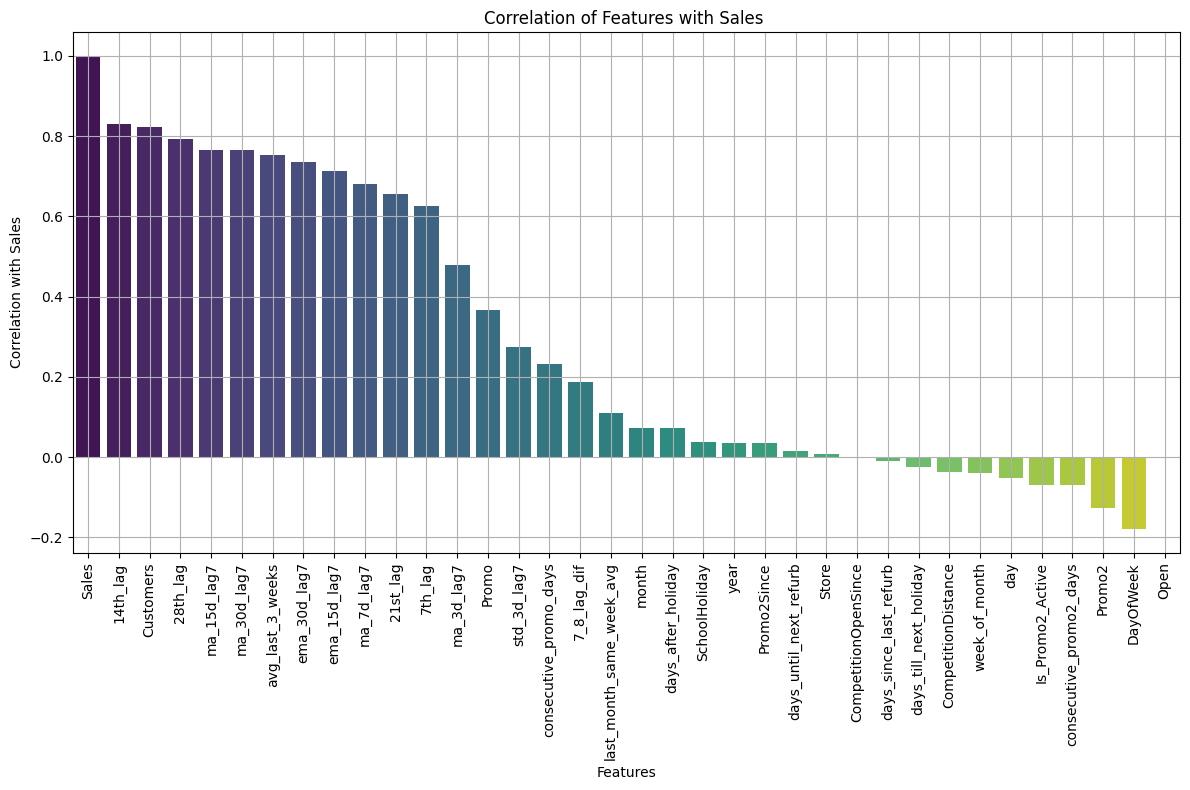

In [101]:
correlation_with_sales = df.select_dtypes(include=np.number).corr()['Sales'].sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=correlation_with_sales.index, y=correlation_with_sales.values, palette='viridis')
plt.title('Correlation of Features with Sales ')
plt.xlabel('Features')
plt.ylabel('Correlation with Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.grid()
plt.show()

<Axes: xlabel='consecutive_promo_days', ylabel='Sales'>

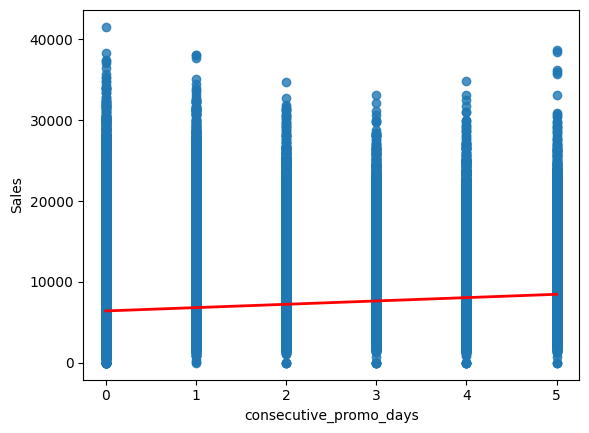

In [102]:
sns.regplot(data=df.reset_index(),x='consecutive_promo_days',y="Sales",ci=None,line_kws={"color": "red", "lw": 2})

In [103]:
df.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 844392 entries, 2013-01-02 to 2015-07-31
Data columns (total 43 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   Store                     844392 non-null  int64   
 1   DayOfWeek                 844392 non-null  int64   
 2   Sales                     844392 non-null  int64   
 3   Customers                 844392 non-null  int64   
 4   Open                      844392 non-null  int64   
 5   Promo                     844392 non-null  int64   
 6   SchoolHoliday             844392 non-null  int64   
 7   year                      844392 non-null  int32   
 8   month                     844392 non-null  int32   
 9   day                       844392 non-null  int32   
 10  StoreType                 844392 non-null  str     
 11  Assortment                844392 non-null  str     
 12  CompetitionDistance       844392 non-null  float64 
 13  Promo2                  

In [104]:
numeric_df = df.select_dtypes(include=['int','float'])
numeric_df.columns


Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'CompetitionDistance',
       'Promo2', 'consecutive_promo_days', 'days_since_last_refurb',
       'days_until_next_refurb', '7th_lag', '14th_lag', '21st_lag', '28th_lag',
       'avg_last_3_weeks', 'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7',
       'ma_15d_lag7', 'ma_30d_lag7', 'ema_15d_lag7', 'ema_30d_lag7',
       '7_8_lag_dif', 'Is_Promo2_Active', 'consecutive_promo2_days',
       'CompetitionOpenSince', 'Promo2Since', 'last_month_same_week_avg',
       'days_till_next_holiday', 'days_after_holiday'],
      dtype='str')

In [105]:
lags=['7th_lag', '14th_lag', '21st_lag', '28th_lag',
       'avg_last_3_weeks', 'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7',
       'ma_15d_lag7', 'ma_30d_lag7', 'ema_15d_lag7', 'ema_30d_lag7','7_8_lag_dif']

['7_8_lag_dif','days_since_last_refurb','days_until_next_refurb','is_quarter_end','last_month_same_week_avg','ema_15d_lag7','ema_30d_lag7']

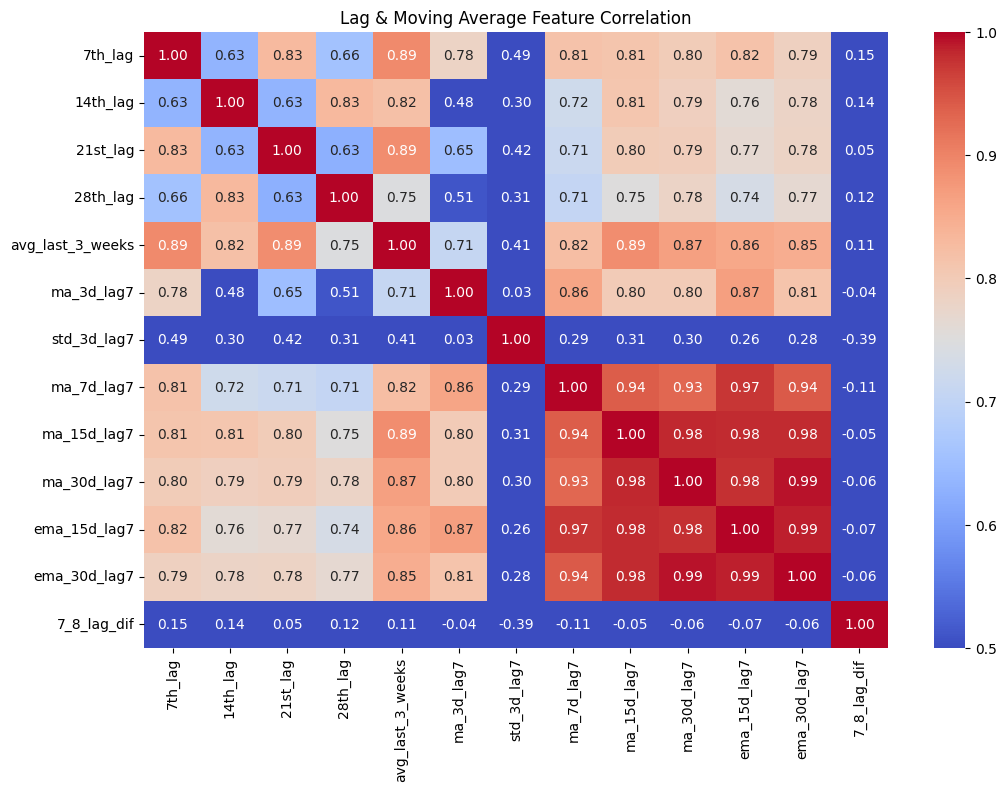

In [106]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[lags].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=0.5, vmax=1.0)
plt.title('Lag & Moving Average Feature Correlation')
plt.show()

In [107]:
# df['Sale_Customer_ratio']=df['Sales']/df['Customers']

In [108]:
#sns.histplot(data=df['x_test'])

In [109]:
# plt.figure(figsize=(15, 4))
# sns.lineplot(x=df['Date'].unique(), y=df.groupby(df['Date'])['Sale_cust_ratio'].mean())

In [110]:
df.reset_index(inplace=True)

In [111]:
['7_8_lag_dif','days_since_last_refurb','days_until_next_refurb','is_quarter_end','last_month_same_week_avg']

['7_8_lag_dif',
 'days_since_last_refurb',
 'days_until_next_refurb',
 'is_quarter_end',
 'last_month_same_week_avg']

In [112]:
def encode_cyclical_feature(df, col, max_val):
    df[col + '_sin'] = np.sin(2 * np.pi * df[col] / max_val)
    df[col + '_cos'] = np.cos(2 * np.pi * df[col] / max_val)
    df.drop(columns=[col], inplace=True)
    return df

In [113]:
df['DayOfWeek'].unique()

array([3, 4, 5, 6, 1, 2, 7])

In [114]:
df[(df['StoreType'] == 'b') & (df['DayOfWeek'] == 7)]

,Date,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,year,month,...,CompetitionOpenSince,Promo2Since,week_of_month,last_month_same_week_avg,promo_x_dayofweek,promo_x_storetype,promo2_x_dayofweek,promo2_x_storetype,days_till_next_holiday,days_after_holiday
63456,2013-01-06,85,7,10509,1509,1,0,0,2013,1,...,463,223,1,NaN,0_7,0_b,0_7,0_b,0.0,0.0
63463,2013-01-13,85,7,10584,1499,1,0,0,2013,1,...,470,230,2,NaN,0_7,0_b,0_7,0_b,18.0,2.0
63470,2013-01-20,85,7,11390,1536,1,0,0,2013,1,...,477,237,3,NaN,0_7,0_b,0_7,0_b,11.0,9.0
63477,2013-01-27,85,7,7522,1049,1,0,0,2013,1,...,484,244,4,NaN,0_7,0_b,0_7,0_b,4.0,16.0
63484,2013-02-03,85,7,13302,1779,1,0,0,2013,2,...,491,251,1,6626.534517,0_7,0_b,0_7,0_b,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
830827,2015-06-28,1097,7,13460,2727,1,0,0,2015,6,...,4867,1126,4,6616.064362,0_7,0_b,0_7,0_b,1.0,23.0
830834,2015-07-05,1097,7,14188,3116,1,0,0,2015,7,...,4874,1133,1,8511.465143,0_7,0_b,0_7,0_b,1.0,2.0
830841,2015-07-12,1097,7,13229,2686,1,0,0,2015,7,...,4881,1140,2,6056.074107,0_7,0_b,0_7,0_b,1.0,2.0
830848,2015-07-19,1097,7,13570,2916,1,0,0,2015,7,...,4888,1147,3,7908.791691,0_7,0_b,0_7,0_b,1.0,2.0


In [115]:
df[(df['StoreType'] == 'b')]['DayOfWeek'].unique()

array([2, 3, 4, 5, 6, 7, 1])

In [116]:
# df=encode_cyclical_feature(df, 'DayOfWeek', 7)

14th_lag                     15534
7th_lag                      13024
21st_lag                      9057
28th_lag                      4377
last_month_same_week_avg      2230

In [117]:
df.reset_index(inplace=True)

In [118]:
store_day_means = (
    df[(df['Date'].dt.year <=2014) & (df['Open']==1)]
    .groupby(['Store', 'DayOfWeek'])['Sales']
    .mean()
    .reset_index()
    .rename(columns={'Sales': 'store_day_mean'})
)

# 2. Merge back to the full dataset (populates both train and test)
df = df.merge(store_day_means, on=['Store', 'DayOfWeek'], how='left')

In [119]:
lag_cols = ['7th_lag', '14th_lag', '21st_lag', '28th_lag']

for col in lag_cols:
    df[col] = df[col].fillna(df['store_day_mean'])

In [120]:
df.drop(columns=['store_day_mean'], inplace=True) 

In [121]:
df.drop(columns=['index'], inplace=True) if 'index' in df.columns else None

In [122]:
df.isna().sum().sort_values(ascending=False)

days_until_next_refurb      818552
days_since_last_refurb      803406
7_8_lag_dif                 186674
last_month_same_week_avg     34544
ma_30d_lag7                  24419
ma_15d_lag7                  14436
ma_7d_lag7                   11121
std_3d_lag7                   7788
ma_3d_lag7                    7788
ema_30d_lag7                  5578
ema_15d_lag7                  5578
avg_last_3_weeks              5578
StoreType                        0
day                              0
month                            0
year                             0
SchoolHoliday                    0
Promo                            0
Open                             0
Customers                        0
Sales                            0
DayOfWeek                        0
Store                            0
Date                             0
7th_lag                          0
consecutive_promo_days           0
Promo2                           0
Assortment                       0
21st_lag            

In [123]:
# df['StoreType'] = df['StoreType'].replace({'a': 0, 'b': 1, 'c': 2,'d': 3})

In [124]:
# df['Assortment'] = df['Assortment'].replace({'Basic': 0, 'Extended': 1, 'Extra': 2})

In [125]:
# corr=df.corr()


In [126]:
# val=corr > 0.85
# plt.figure(figsize=(18, 14))
# sns.heatmap(val, annot=True, cmap='coolwarm', linewidths=0.5)

In [127]:
df['Assortment'] = df['Assortment'].astype('category')
df['StoreType'] = df['StoreType'].astype('category')

In [128]:
# split_date= '2014-12-31'
# print(f'Number of rows in training set: {df[df.index <= split_date].shape[0]}')
# print(f'Number of rows in test set: {df[df.index > split_date].shape[0]}')

In [129]:
264280*0.2

52856.0

In [130]:
182885+81395

264280

In [131]:
df.reset_index(inplace=True)
# Shuffles rows and resets the index counter
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


In [132]:
df.drop(columns=['index'], inplace=True) if 'index' in df.columns else None

In [133]:
df.drop(columns=['Promo2Since','CompetitionOpenSince'], inplace=True) 

In [134]:
df.columns

Index(['Date', 'Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'Promo2', 'quarter', 'consecutive_promo_days',
       'days_since_last_refurb', 'days_until_next_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks', 'ma_3d_lag7',
       'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7', 'ma_30d_lag7',
       'ema_15d_lag7', 'ema_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days', 'week_of_month', 'last_month_same_week_avg',
       'promo_x_dayofweek', 'promo_x_storetype', 'promo2_x_dayofweek',
       'promo2_x_storetype', 'days_till_next_holiday', 'days_after_holiday'],
      dtype='str')

In [135]:
categorical_feature=['Assortment','StoreType','DayOfWeek','month','Store','promo_x_dayofweek','promo_x_storetype']
df[categorical_feature] = df[categorical_feature].astype('category')

df = df.astype({'SchoolHoliday': np.int8, 'month' : np.int8,'day' : np.int8, 'consecutive_promo_days' : np.int16,
                'Customers' : np.int32, 'Sales' : np.int32, 'Promo' : np.int8 ,'Promo2' : np.int8
                })

In [136]:
df=df[df['Sales'] >0]

In [137]:
# import pandas as pd
# from sklearn.feature_selection import RFECV
# from sklearn.preprocessing import OrdinalEncoder
# from xgboost import XGBRegressor

# # 1. Separate features and target
# X = x_test_augmented_sales
# y = y_test_sales

# # 2. Encode categorical columns into numeric integers
# categorical_cols = X.select_dtypes(include=['object', 'category']).columns

# encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
# X_encoded = X.copy()
# X_encoded[categorical_cols] = encoder.fit_transform(X[categorical_cols])

# # 3. Run RFECV with a GBDT estimator
# estimator = XGBRegressor(n_estimators=100, random_state=42)
# rfecv = RFECV(
#     estimator=estimator,
#     step=1,
#     cv=3,
#     scoring='neg_mean_absolute_error',
#     n_jobs=-1
# )

# rfecv.fit(X_encoded, y)

# # Selected features
# selected_features = X_encoded.columns[rfecv.support_]
# print(f"Optimal number of features: {rfecv.n_features_}")
# print(f"Selected features: {list(selected_features)}")

In [138]:
df.drop(columns=['quarter',
 'week_of_month',
 'year','Open',
 'days_until_next_refurb'],inplace=True)
df.drop(columns=['ema_15d_lag7', 'ema_30d_lag7'],inplace=True)

In [139]:
df.rename(columns={"Date": "Sales_date"}, inplace=True)


In [140]:
stop

NameError: name 'stop' is not defined

In [ ]:
#df.to_parquet('final_data.parquet')

In [142]:
import sqlite3
db_filename = r"DB\Sales_data.db"
conn = sqlite3.connect(db_filename)

try:
    # 3. Stream the DataFrame data straight into an SQLite table
    # Set index=False to prevent Pandas from creating an extra column for row numbers
    # Set if_exists='replace' to overwrite existing records or 'append' to add to them
    df.to_sql(
        name="Sales_Data", 
        con=conn, 
        if_exists="replace", 
        index=False
    )
    print(f"✅ Successfully transferred data from Parquet to table 'Sales_Data' in '{db_filename}'")

finally:
    # Always explicitly close database connections to prevent memory leaks or locking issues
    conn.close()

✅ Successfully transferred data from Parquet to table 'Sales_Data' in 'DB\Sales_data.db'


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 844392 entries, 0 to 844391
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Date                      844392 non-null  datetime64[us]
 1   Store                     844392 non-null  category      
 2   DayOfWeek                 844392 non-null  category      
 3   Sales                     844392 non-null  int32         
 4   Customers                 844392 non-null  int32         
 5   Promo                     844392 non-null  int8          
 6   SchoolHoliday             844392 non-null  int8          
 7   month                     844392 non-null  int8          
 8   day                       844392 non-null  int8          
 9   StoreType                 844392 non-null  category      
 10  Assortment                844392 non-null  category      
 11  CompetitionDistance       844392 non-null  float64       
 12  Promo2       